# Fine-tune DeBERTa for Joint Aspect-Sentiment Multilabel Classification

This notebook uses the cleaned Trustpilot dataset output:

```text
01_trustpilot_reformatted_wide_light_preprocessed.csv
```

The goal is to fine-tune **one DeBERTa model** that predicts **aspect + sentiment together**.

The Trustpilot aspect columns use this meaning:

```text
NaN = aspect is not present
1   = aspect is present with positive sentiment
0   = aspect is present with negative sentiment
```

Therefore, the notebook converts the 14 aspect columns into 28 joint multilabel targets:

```text
Shipping_Positive
Shipping_Negative
Trust_Positive
Trust_Negative
...
```

## Best suggestion

Use this notebook as the main one-model ABSA experiment. It preserves the original Trustpilot labels and only changes the format into a model-friendly joint multilabel format.

## Pros

- One model learns aspect detection and aspect-level sentiment together.
- One saved checkpoint is enough for inference.
- The output is already in ABSA format, for example `Shipping:Negative; Item_quality:Positive`.

## Cons

- Some labels are rare, so the model may struggle on minority aspect-sentiment pairs.
- Because positive and negative labels are predicted independently, conflict resolution is needed if the model predicts both polarities for the same aspect.
- Evaluation needs multilabel metrics, not normal single-label accuracy only.

In [ ]:
# # ============================================================
# # 0. Optional package installation
# # ============================================================
# # Set INSTALL_PACKAGES = True only if your environment is missing packages.
# # In your local VS Code environment, you likely already have torch + transformers installed.

# INSTALL_PACKAGES = False

# if INSTALL_PACKAGES:
#     %pip install -q "transformers>=4.36.2" accelerate sentencepiece protobuf scikit-learn pandas numpy matplotlib tqdm

In [1]:
# ============================================================
# 1. Imports and global settings
# ============================================================

import os
import json
import random
import shutil
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    hamming_loss,
    classification_report,
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    set_seed,
)

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [2]:
# ============================================================
# 2. Path configuration
# ============================================================
# This notebook looks for the 01 dataset in several possible locations.
# You can also directly edit DATA_PATH if needed.

CANDIDATE_DATA_PATHS = [
    os.environ.get("TRUSTPILOT_WIDE_PATH", ""),
    "01_trustpilot_reformatted_wide_light_preprocessed.csv",
    "./trustpilot_reformatted_output/01_trustpilot_reformatted_wide_light_preprocessed.csv",
    "../trustpilot_reformatted_output/01_trustpilot_reformatted_wide_light_preprocessed.csv",
    r"C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\01_trustpilot_reformatted_wide_light_preprocessed.csv",
    "/mnt/data/01_trustpilot_reformatted_wide_light_preprocessed.csv",
]

DATA_PATH = None
for candidate in CANDIDATE_DATA_PATHS:
    if candidate and Path(candidate).exists():
        DATA_PATH = Path(candidate)
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find 01_trustpilot_reformatted_wide_light_preprocessed.csv. "
        "Please edit DATA_PATH manually."
    )

OUTPUT_DIR = DATA_PATH.parent / "deberta_joint_aspect_sentiment_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RUNS_DIR = OUTPUT_DIR / "tuning_runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_DIR = OUTPUT_DIR / "best_joint_deberta_model"

print("DATA_PATH:", DATA_PATH)
print("OUTPUT_DIR:", OUTPUT_DIR)

DATA_PATH: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\01_trustpilot_reformatted_wide_light_preprocessed.csv
OUTPUT_DIR: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output


In [3]:
if DATA_PATH is None:
    raise FileNotFoundError(
        "DATA_PATH is None. Please set DATA_PATH to the correct CSV file path."
    )

DATA_PATH = Path(DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset file not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print("Dataset path:", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head(3))
print(df.columns.tolist())

Dataset path: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\01_trustpilot_reformatted_wide_light_preprocessed.csv
Dataset shape: (2782, 28)


,Card_id,Rating,Location,Date,Total Review,shop,Year,General,General_text,text_raw,...,Pricing,Product_availability,Payment,Packaging,Delivered_product_status,Shipping,Return_process,Refund_process,Customer_service,Trust
0,591ed0daa02b420900675219,5,Britain (UK),2017-05-19,1 review,Zalando,2017,1.0,Positive,Excellent and well organised. Excellent and we...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
1,5b7af35f14b7d805ec7389c4,1,Britain (UK),2018-08-20,3 reviews,Zalando,2018,0.0,Negative,Bizarre returns service.,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
2,5fe77011755dc107e0cf497f,1,Finland,2020-12-26,1 review,Zalando,2020,0.0,Negative,I have ordered jacket and then returned…. I ha...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0


['Card_id', 'Rating', 'Location', 'Date', 'Total Review', 'shop', 'Year', 'General', 'General_text', 'text_raw', 'text_clean', 'aspect_count', 'positive_aspect_count', 'negative_aspect_count', 'Information', 'Product_features', 'Item_quality', 'App_experience', 'Pricing', 'Product_availability', 'Payment', 'Packaging', 'Delivered_product_status', 'Shipping', 'Return_process', 'Refund_process', 'Customer_service', 'Trust']


In [4]:
# ============================================================
# 4. Define Trustpilot aspect columns
# ============================================================

ASPECT_COLS = [
    "Information",
    "Product_features",
    "Item_quality",
    "App_experience",
    "Pricing",
    "Product_availability",
    "Payment",
    "Packaging",
    "Delivered_product_status",
    "Shipping",
    "Return_process",
    "Refund_process",
    "Customer_service",
    "Trust",
]

missing_cols = [c for c in ASPECT_COLS if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing aspect columns: {missing_cols}")

TEXT_COL = "text_clean"
if TEXT_COL not in df.columns:
    raise ValueError(f"Text column '{TEXT_COL}' was not found.")

print("Number of aspects:", len(ASPECT_COLS))
print("Aspect columns:")
for c in ASPECT_COLS:
    print("-", c)

Number of aspects: 14
Aspect columns:
- Information
- Product_features
- Item_quality
- App_experience
- Pricing
- Product_availability
- Payment
- Packaging
- Delivered_product_status
- Shipping
- Return_process
- Refund_process
- Customer_service
- Trust


## 5. Convert original aspect columns into joint aspect-sentiment labels

For each aspect:

```text
aspect value = 1   → Aspect_Positive = 1, Aspect_Negative = 0
aspect value = 0   → Aspect_Positive = 0, Aspect_Negative = 1
aspect value = NaN → Aspect_Positive = 0, Aspect_Negative = 0
```

This creates a 28-label multilabel target.

In [5]:
# ============================================================
# 5. Build joint aspect-sentiment multilabel dataset
# ============================================================

work_df = df.copy()

JOINT_LABEL_COLS = []
for aspect in ASPECT_COLS:
    pos_col = f"{aspect}_Positive"
    neg_col = f"{aspect}_Negative"
    work_df[pos_col] = (work_df[aspect] == 1).astype(int)
    work_df[neg_col] = (work_df[aspect] == 0).astype(int)
    JOINT_LABEL_COLS.extend([pos_col, neg_col])

work_df[TEXT_COL] = work_df[TEXT_COL].fillna("").astype(str).str.strip()
work_df["joint_label_count"] = work_df[JOINT_LABEL_COLS].sum(axis=1)

model_df = work_df[(work_df[TEXT_COL] != "") & (work_df["joint_label_count"] > 0)].copy().reset_index(drop=True)

print("Original rows:", len(df))
print("Rows usable for joint model:", len(model_df))
print("Number of joint labels:", len(JOINT_LABEL_COLS))

label_counts = model_df[JOINT_LABEL_COLS].sum().sort_values(ascending=False)
zero_positive_labels = label_counts[label_counts == 0].index.tolist()

print("\nTop labels:")
display(label_counts.head(15).to_frame("positive_count"))

print("\nLabels with zero positive training examples:")
print(zero_positive_labels if zero_positive_labels else "None")

JOINT_DATASET_PATH = OUTPUT_DIR / "11_trustpilot_joint_aspect_sentiment_multilabel.csv"
columns_to_save = [
    "Card_id", "Rating", "Location", "Date", "Total Review", "shop", "Year",
    "General", "General_text", "text_raw", "text_clean", "aspect_count",
    "positive_aspect_count", "negative_aspect_count", "joint_label_count",
] + ASPECT_COLS + JOINT_LABEL_COLS
columns_to_save = [c for c in columns_to_save if c in model_df.columns]
model_df[columns_to_save].to_csv(JOINT_DATASET_PATH, index=False, encoding="utf-8-sig")
print("Saved joint dataset:", JOINT_DATASET_PATH)

Original rows: 2782
Rows usable for joint model: 2782
Number of joint labels: 28

Top labels:


,positive_count
Shipping_Positive,873
Trust_Positive,744
Shipping_Negative,642
Item_quality_Positive,628
Trust_Negative,437
Pricing_Positive,416
Customer_service_Negative,341
Customer_service_Positive,308
Product_availability_Positive,218
Refund_process_Negative,188



Labels with zero positive training examples:
['Packaging_Positive']
Saved joint dataset: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\11_trustpilot_joint_aspect_sentiment_multilabel.csv


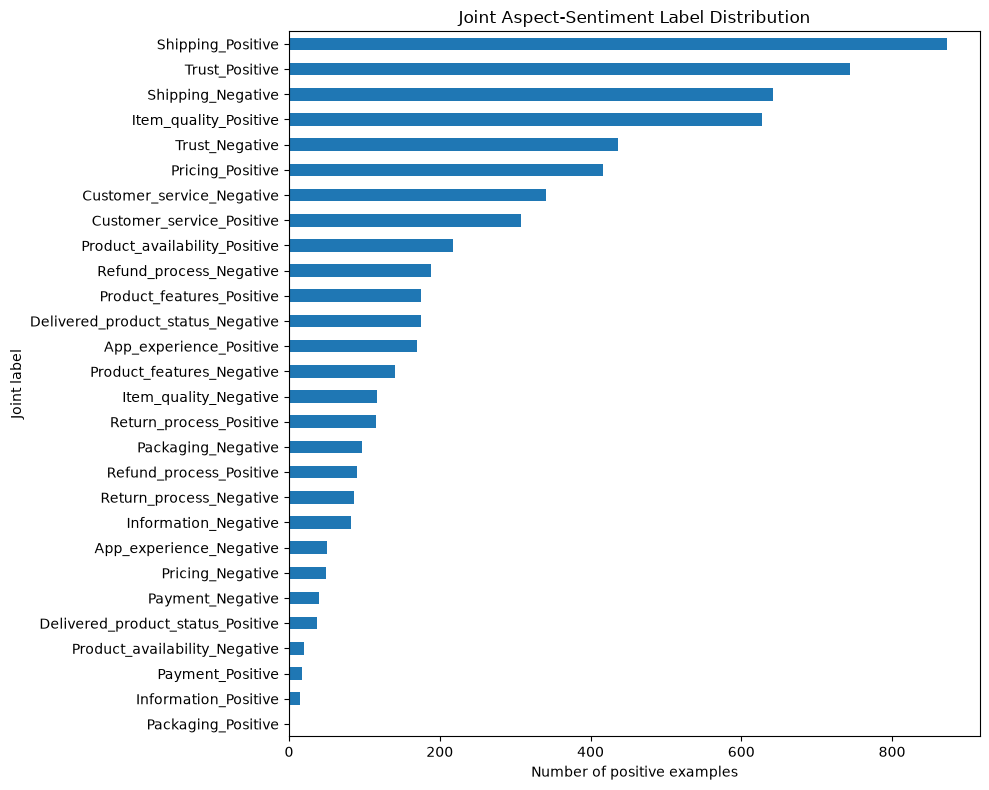

In [6]:
# ============================================================
# 6. Visualize joint label distribution
# ============================================================

plt.figure(figsize=(10, 8))
label_counts.sort_values().plot(kind="barh")
plt.title("Joint Aspect-Sentiment Label Distribution")
plt.xlabel("Number of positive examples")
plt.ylabel("Joint label")
plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# 7. Train / validation / test split
# ============================================================
# Multilabel stratification needs extra libraries. To keep the notebook portable,
# we use a reproducible random split and then save/check label distributions.

train_df, temp_df = train_test_split(
    model_df,
    test_size=0.20,
    random_state=SEED,
    shuffle=True,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    shuffle=True,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

split_summary = pd.DataFrame({
    "label": JOINT_LABEL_COLS,
    "train_count": train_df[JOINT_LABEL_COLS].sum().astype(int).values,
    "val_count": val_df[JOINT_LABEL_COLS].sum().astype(int).values,
    "test_count": test_df[JOINT_LABEL_COLS].sum().astype(int).values,
})
split_summary["total_count"] = split_summary[["train_count", "val_count", "test_count"]].sum(axis=1)

SPLIT_SUMMARY_PATH = OUTPUT_DIR / "12_joint_label_split_distribution.csv"
split_summary.to_csv(SPLIT_SUMMARY_PATH, index=False, encoding="utf-8-sig")
display(split_summary)
print("Saved split distribution:", SPLIT_SUMMARY_PATH)

Train: (2225, 57)
Validation: (278, 57)
Test: (279, 57)


,label,train_count,val_count,test_count,total_count
0,Information_Positive,9,5,1,15
1,Information_Negative,71,5,6,82
2,Product_features_Positive,133,24,18,175
3,Product_features_Negative,109,15,17,141
4,Item_quality_Positive,498,63,67,628
5,Item_quality_Negative,97,11,9,117
6,App_experience_Positive,135,14,21,170
7,App_experience_Negative,44,2,5,51
8,Pricing_Positive,341,26,49,416
9,Pricing_Negative,41,3,5,49


Saved split distribution: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\12_joint_label_split_distribution.csv


In [11]:
# ============================================================
# 8. Dataset class
# ============================================================

class TrustpilotJointDataset(torch.utils.data.Dataset):
    def __init__(self, dataframe, tokenizer, max_length, text_col, label_cols):
        self.texts = dataframe[text_col].fillna("").astype(str).tolist()
        self.labels = dataframe[label_cols].astype(np.float32).values
        self.encodings = tokenizer(
            self.texts,
            truncation=True,
            padding="max_length",
            max_length=max_length,
        )

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.float32)
        return item

In [12]:
# ============================================================
# 9. Metrics and conflict resolution
# ============================================================

def sigmoid_np(x):
    return 1 / (1 + np.exp(-x))


def apply_threshold_with_conflict_resolution(probs, threshold, label_cols, aspect_cols):
    """
    Convert probabilities to binary predictions.
    If both Positive and Negative are predicted for the same aspect,
    keep only the polarity with the higher probability.
    """
    preds = (probs >= threshold).astype(int)
    label_to_idx = {label: i for i, label in enumerate(label_cols)}
    conflict_count = 0

    for row_idx in range(preds.shape[0]):
        for aspect in aspect_cols:
            pos_label = f"{aspect}_Positive"
            neg_label = f"{aspect}_Negative"

            if pos_label not in label_to_idx or neg_label not in label_to_idx:
                continue

            pos_idx = label_to_idx[pos_label]
            neg_idx = label_to_idx[neg_label]

            if preds[row_idx, pos_idx] == 1 and preds[row_idx, neg_idx] == 1:
                conflict_count += 1

                if probs[row_idx, pos_idx] >= probs[row_idx, neg_idx]:
                    preds[row_idx, neg_idx] = 0
                else:
                    preds[row_idx, pos_idx] = 0

    return preds, conflict_count


def multilabel_metrics(y_true, probs, threshold, label_cols, aspect_cols):
    y_pred, conflict_count = apply_threshold_with_conflict_resolution(
        probs=probs,
        threshold=threshold,
        label_cols=label_cols,
        aspect_cols=aspect_cols,
    )

    metrics = {
        "threshold": float(threshold),
        "micro_f1": float(f1_score(y_true, y_pred, average="micro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "samples_f1": float(f1_score(y_true, y_pred, average="samples", zero_division=0)),
        "micro_precision": float(precision_score(y_true, y_pred, average="micro", zero_division=0)),
        "micro_recall": float(recall_score(y_true, y_pred, average="micro", zero_division=0)),
        "exact_match_accuracy": float(accuracy_score(y_true, y_pred)),
        "hamming_loss": float(hamming_loss(y_true, y_pred)),
        "avg_true_labels_per_review": float(y_true.sum(axis=1).mean()),
        "avg_pred_labels_per_review": float(y_pred.sum(axis=1).mean()),
        "conflict_count_before_resolution": int(conflict_count),
    }

    return metrics, y_pred


def tune_global_threshold(y_true, probs, label_cols, aspect_cols, thresholds=None):
    """
    Find the best single/global threshold for all joint labels.

    Selection priority:
    1. Highest macro F1
    2. Highest micro F1
    3. Lowest hamming loss
    """
    if thresholds is None:
        thresholds = np.round(np.arange(0.20, 0.81, 0.05), 2)

    thresholds = list(thresholds)

    if len(thresholds) == 0:
        raise ValueError("thresholds is empty. Provide at least one threshold value.")

    rows = []
    best_score = None
    best_metrics = None

    for threshold in thresholds:
        metrics, _ = multilabel_metrics(
            y_true=y_true,
            probs=probs,
            threshold=threshold,
            label_cols=label_cols,
            aspect_cols=aspect_cols,
        )

        rows.append(metrics)

        score_tuple = (
            metrics["macro_f1"],
            metrics["micro_f1"],
            -metrics["hamming_loss"],
        )

        if best_score is None or score_tuple > best_score:
            best_score = score_tuple
            best_metrics = metrics

    if best_metrics is None:
        raise RuntimeError("No best threshold was selected. Check threshold tuning logic.")

    return best_metrics, pd.DataFrame(rows)


def decode_joint_labels(binary_row, label_cols):
    decoded = []

    for value, label in zip(binary_row, label_cols):
        if int(value) == 1:
            aspect, sentiment = label.rsplit("_", 1)
            decoded.append(f"{aspect}:{sentiment}")

    return "; ".join(decoded)


def make_prediction_dataframe(dataframe, y_true, y_pred, probs, label_cols, output_path):
    keep_cols = [
        c for c in ["Card_id", "shop", "Rating", "General_text", "text_clean"]
        if c in dataframe.columns
    ]

    pred_df = dataframe[keep_cols].copy()

    pred_df["true_aspect_sentiment"] = [
        decode_joint_labels(row, label_cols) for row in y_true
    ]

    pred_df["pred_aspect_sentiment"] = [
        decode_joint_labels(row, label_cols) for row in y_pred
    ]

    for idx, label in enumerate(label_cols):
        pred_df[f"prob_{label}"] = probs[:, idx]

    pred_df.to_csv(output_path, index=False, encoding="utf-8-sig")

    return pred_df

In [13]:
# ============================================================
# 10. Custom trainer with optional multilabel positive class weights
# ============================================================

class WeightedMultilabelTrainer(Trainer):
    def __init__(self, *args, pos_weight_tensor=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.pos_weight_tensor = pos_weight_tensor

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None,
    ):
        _ = num_items_in_batch

        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        if self.pos_weight_tensor is not None:
            loss_fct = nn.BCEWithLogitsLoss(
                pos_weight=self.pos_weight_tensor.to(
                    device=logits.device,
                    dtype=torch.float32,
                )
            )
        else:
            loss_fct = nn.BCEWithLogitsLoss()

        loss = loss_fct(logits.float(), labels.float())

        return (loss, outputs) if return_outputs else loss


def make_pos_weight(train_dataframe, label_cols, cap=20.0):
    """
    Create positive-class weights for multilabel classification.

    For each label:
        pos_weight = negative_count / positive_count

    This makes rare positive labels receive higher loss weight.
    The cap prevents extremely large weights from making training unstable.
    """
    y = train_dataframe[label_cols].astype(np.float32).values

    pos = y.sum(axis=0)
    neg = y.shape[0] - pos

    weights = []
    for positive_count, negative_count in zip(pos, neg):
        if positive_count <= 0:
            weights.append(1.0)
        else:
            weight = float(negative_count / positive_count)
            weights.append(min(weight, cap))

    return torch.tensor(weights, dtype=torch.float32)

In [14]:
# ============================================================
# 11. Training configuration grid
# ============================================================
# Start with these 3 settings. On an RTX 3050 4GB GPU, batch size 4 is safer.
# If you get CUDA out-of-memory, reduce max_length to 128 or train_batch_size to 2.

MODEL_NAME = "microsoft/deberta-v3-small"

RUN_CONFIGS = [
    {
        "run_name": "deberta_joint_lr2e-5_len160_weighted",
        "learning_rate": 2e-5,
        "num_train_epochs": 4,
        "max_length": 160,
        "per_device_train_batch_size": 4,
        "per_device_eval_batch_size": 8,
        "gradient_accumulation_steps": 2,
        "weight_decay": 0.01,
        "use_pos_weight": True,
        "pos_weight_cap": 20.0,
    },
    {
        "run_name": "deberta_joint_lr1e-5_len192_weighted",
        "learning_rate": 1e-5,
        "num_train_epochs": 5,
        "max_length": 192,
        "per_device_train_batch_size": 4,
        "per_device_eval_batch_size": 8,
        "gradient_accumulation_steps": 2,
        "weight_decay": 0.01,
        "use_pos_weight": True,
        "pos_weight_cap": 20.0,
    },
    {
        "run_name": "deberta_joint_lr3e-5_len160_unweighted",
        "learning_rate": 3e-5,
        "num_train_epochs": 4,
        "max_length": 160,
        "per_device_train_batch_size": 4,
        "per_device_eval_batch_size": 8,
        "gradient_accumulation_steps": 2,
        "weight_decay": 0.01,
        "use_pos_weight": False,
        "pos_weight_cap": 20.0,
    },
]

FAST_DEBUG = False

if FAST_DEBUG:
    train_df = train_df.sample(min(128, len(train_df)), random_state=SEED).reset_index(drop=True)
    val_df = val_df.sample(min(64, len(val_df)), random_state=SEED).reset_index(drop=True)
    test_df = test_df.sample(min(64, len(test_df)), random_state=SEED).reset_index(drop=True)
    RUN_CONFIGS = [dict(RUN_CONFIGS[0], num_train_epochs=1, run_name="debug_deberta_joint")]

print("Number of run configs:", len(RUN_CONFIGS))
display(pd.DataFrame(RUN_CONFIGS))

Number of run configs: 3


,run_name,learning_rate,num_train_epochs,max_length,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,use_pos_weight,pos_weight_cap
0,deberta_joint_lr2e-5_len160_weighted,0.00002,4,160,4,8,2,0.01,True,20.0
1,deberta_joint_lr1e-5_len192_weighted,0.00001,5,192,4,8,2,0.01,True,20.0
2,deberta_joint_lr3e-5_len160_unweighted,0.00003,4,160,4,8,2,0.01,False,20.0


In [12]:
# ============================================================
# 12. Run hyperparameter tuning
# ============================================================

from IPython.display import display

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

id2label = {i: label for i, label in enumerate(JOINT_LABEL_COLS)}
label2id = {label: i for i, label in id2label.items()}

all_results = []
best_overall = None

RUNS_DIR = Path(RUNS_DIR)
OUTPUT_DIR = Path(OUTPUT_DIR)

for run_idx, cfg in enumerate(RUN_CONFIGS, start=1):
    run_name = str(cfg["run_name"])

    print("\n" + "=" * 90)
    print(f"[{datetime.now().strftime('%Y-%m-%d %H:%M:%S')}] Starting run {run_idx}/{len(RUN_CONFIGS)}")
    print(json.dumps(cfg, indent=2))
    print("=" * 90)

    run_dir = RUNS_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    train_dataset = TrustpilotJointDataset(
        train_df,
        tokenizer,
        int(cfg["max_length"]),
        TEXT_COL,
        JOINT_LABEL_COLS,
    )

    val_dataset = TrustpilotJointDataset(
        val_df,
        tokenizer,
        int(cfg["max_length"]),
        TEXT_COL,
        JOINT_LABEL_COLS,
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(JOINT_LABEL_COLS),
        problem_type="multi_label_classification",
        id2label=id2label,
        label2id=label2id,
    )

    model.float()
    print("Model dtype:", next(model.parameters()).dtype)

    pos_weight_tensor = None
    if bool(cfg.get("use_pos_weight", False)):
        pos_weight_tensor = make_pos_weight(
            train_df,
            JOINT_LABEL_COLS,
            cap=float(cfg.get("pos_weight_cap", 20.0)),
        )

        pos_weight_df = pd.DataFrame({
            "label": JOINT_LABEL_COLS,
            "pos_weight": pos_weight_tensor.cpu().numpy(),
        })

        pos_weight_df.to_csv(
            run_dir / "pos_weights.csv",
            index=False,
            encoding="utf-8-sig",
        )

    def compute_metrics_fixed_050(eval_pred):
        logits, labels = eval_pred
        probs = sigmoid_np(logits)

        metrics, _ = multilabel_metrics(
            labels,
            probs,
            threshold=0.50,
            label_cols=JOINT_LABEL_COLS,
            aspect_cols=ASPECT_COLS,
        )

        return {
            "micro_f1": metrics["micro_f1"],
            "macro_f1": metrics["macro_f1"],
            "weighted_f1": metrics["weighted_f1"],
            "samples_f1": metrics["samples_f1"],
            "hamming_loss": metrics["hamming_loss"],
        }

    training_args = TrainingArguments(
        output_dir=str(run_dir),
        run_name=run_name,
        learning_rate=float(cfg["learning_rate"]),
        num_train_epochs=int(cfg["num_train_epochs"]),
        per_device_train_batch_size=int(cfg["per_device_train_batch_size"]),
        per_device_eval_batch_size=int(cfg["per_device_eval_batch_size"]),
        gradient_accumulation_steps=int(cfg["gradient_accumulation_steps"]),
        weight_decay=float(cfg["weight_decay"]),

        eval_strategy="epoch",
        save_strategy="epoch",

        logging_strategy="steps",
        logging_steps=25,
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="eval_macro_f1",
        greater_is_better=True,

        # Safer for your current custom Trainer setup
        fp16=False,
        bf16=False,

        # Helpful for 4GB VRAM
        gradient_checkpointing=True,
        eval_accumulation_steps=8,

        report_to="none",
        seed=SEED,
        data_seed=SEED,
        remove_unused_columns=True,
    )

    trainer = WeightedMultilabelTrainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics_fixed_050,
        pos_weight_tensor=pos_weight_tensor,
    )

    train_result = trainer.train()

    val_pred_output = trainer.predict(val_dataset)
    val_logits = val_pred_output.predictions
    val_probs = sigmoid_np(val_logits)
    val_true = val_df[JOINT_LABEL_COLS].astype(int).values

    best_threshold_metrics, threshold_table = tune_global_threshold(
        y_true=val_true,
        probs=val_probs,
        label_cols=JOINT_LABEL_COLS,
        aspect_cols=ASPECT_COLS,
    )

    threshold_table.to_csv(
        run_dir / "threshold_tuning_validation.csv",
        index=False,
        encoding="utf-8-sig",
    )

    run_result = {
        **cfg,
        "run_name": run_name,
        "best_threshold": best_threshold_metrics["threshold"],
        "val_micro_f1_tuned": best_threshold_metrics["micro_f1"],
        "val_macro_f1_tuned": best_threshold_metrics["macro_f1"],
        "val_weighted_f1_tuned": best_threshold_metrics["weighted_f1"],
        "val_samples_f1_tuned": best_threshold_metrics["samples_f1"],
        "val_exact_match_accuracy_tuned": best_threshold_metrics["exact_match_accuracy"],
        "val_hamming_loss_tuned": best_threshold_metrics["hamming_loss"],
        "val_avg_pred_labels_per_review_tuned": best_threshold_metrics["avg_pred_labels_per_review"],
        "val_conflict_count_before_resolution_tuned": best_threshold_metrics["conflict_count_before_resolution"],
        "run_dir": str(run_dir),
    }

    all_results.append(run_result)

    print("\nBest threshold metrics for this run:")
    print(json.dumps(best_threshold_metrics, indent=2))

    score_tuple = (
        run_result["val_macro_f1_tuned"],
        run_result["val_micro_f1_tuned"],
        -run_result["val_hamming_loss_tuned"],
    )

    if best_overall is None or score_tuple > best_overall["score_tuple"]:
        best_overall = {
            "score_tuple": score_tuple,
            "run_result": run_result,
            "trainer": trainer,
            "tokenizer": tokenizer,
            "config": cfg,
            "best_threshold_metrics": best_threshold_metrics,
        }
        print("✅ New best overall model found.")

    tuning_results_df = pd.DataFrame(all_results)
    tuning_results_path = OUTPUT_DIR / "13_hyperparameter_tuning_results.csv"

    tuning_results_df.to_csv(
        tuning_results_path,
        index=False,
        encoding="utf-8-sig",
    )

    display(
        tuning_results_df.sort_values(
            ["val_macro_f1_tuned", "val_micro_f1_tuned"],
            ascending=False,
        )
    )

assert best_overall is not None, "No tuning run was completed. Check RUN_CONFIGS."

print("\nTuning finished.")
print("Best run:", best_overall["run_result"]["run_name"])
print("Best threshold:", best_overall["run_result"]["best_threshold"])
print("Saved tuning results:", OUTPUT_DIR / "13_hyperparameter_tuning_results.csv")


[2026-06-18 22:35:51] Starting run 1/3
{
  "run_name": "deberta_joint_lr2e-5_len160_weighted",
  "learning_rate": 2e-05,
  "num_train_epochs": 4,
  "max_length": 160,
  "per_device_train_batch_size": 4,
  "per_device_eval_batch_size": 8,
  "gradient_accumulation_steps": 2,
  "weight_decay": 0.01,
  "use_pos_weight": true,
  "pos_weight_cap": 20.0
}


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
classifier.weight                       | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.de

Model dtype: torch.float32


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Weighted F1,Samples F1,Hamming Loss,Runtime,Samples Per Second,Steps Per Second
1,1.484288,0.726079,0.397314,0.255692,0.461805,0.392305,0.196043,2.016600,137.856000,17.356000
2,1.171442,0.597448,0.510617,0.336263,0.539386,0.529915,0.127312,2.006300,138.561000,17.445000
3,1.026369,0.556654,0.521034,0.345868,0.551839,0.548213,0.121403,2.007800,138.463000,17.432000
4,0.919184,0.534616,0.523092,0.355055,0.557719,0.551469,0.122045,2.006000,138.582000,17.447000


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Best threshold metrics for this run:
{
  "threshold": 0.2,
  "micro_f1": 0.6483754512635379,
  "macro_f1": 0.35314160058135163,
  "weighted_f1": 0.621846363845245,
  "samples_f1": 0.672539690525302,
  "micro_precision": 0.5719745222929936,
  "micro_recall": 0.7483333333333333,
  "exact_match_accuracy": 0.28776978417266186,
  "hamming_loss": 0.06256423432682426,
  "avg_true_labels_per_review": 2.158273381294964,
  "avg_pred_labels_per_review": 2.823741007194245,
  "conflict_count_before_resolution": 0
}


,run_name,learning_rate,num_train_epochs,max_length,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,use_pos_weight,pos_weight_cap,best_threshold,val_micro_f1_tuned,val_macro_f1_tuned,val_weighted_f1_tuned,val_samples_f1_tuned,val_exact_match_accuracy_tuned,val_hamming_loss_tuned,val_avg_pred_labels_per_review_tuned,val_conflict_count_before_resolution_tuned,run_dir
0,deberta_joint_lr2e-5_len160_weighted,0.00002,4,160,4,8,2,0.01,True,20.0,0.75,0.570728,0.392973,0.553995,0.448702,0.140288,0.067446,2.241007,3,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
2,deberta_joint_lr3e-5_len160_unweighted,0.00003,4,160,4,8,2,0.01,False,20.0,0.20,0.648375,0.353142,0.621846,0.672540,0.287770,0.062564,2.823741,0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
1,deberta_joint_lr1e-5_len192_weighted,0.00001,5,192,4,8,2,0.01,True,20.0,0.70,0.497085,0.342747,0.500081,0.387928,0.093525,0.088643,2.776978,3,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...



Tuning finished.
Best run: deberta_joint_lr2e-5_len160_weighted
Best threshold: 0.75
Saved tuning results: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\13_hyperparameter_tuning_results.csv


In [18]:
# ============================================================
# 13B. Stage-2 experiment setup: improved configs + per-label threshold tuning
# ============================================================

import gc

def clean_gpu_memory():
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        try:
            torch.cuda.ipc_collect()
        except Exception:
            pass


# Remove old stored trainer/model reference from Cell 12 to free GPU memory.
# This keeps the old CSV result, but releases the old model object.
try:
    if isinstance(best_overall, dict):
        best_overall.pop("trainer", None)
        best_overall.pop("tokenizer", None)
except NameError:
    pass

for old_name in ["trainer", "model", "train_dataset", "val_dataset", "val_pred_output"]:
    if old_name in globals():
        del globals()[old_name]

clean_gpu_memory()

In [20]:
def make_threshold_vector(thresholds, label_cols):
    """
    Accept scalar threshold, dict threshold, list threshold, or numpy array threshold.
    Return one threshold value per joint label.
    """
    if isinstance(thresholds, dict):
        return np.array([float(thresholds[label]) for label in label_cols], dtype=np.float32)

    threshold_array = np.asarray(thresholds, dtype=np.float32)

    if threshold_array.ndim == 0:
        threshold_array = np.full(len(label_cols), float(threshold_array), dtype=np.float32)

    if len(threshold_array) != len(label_cols):
        raise ValueError(
            f"Threshold length mismatch. Expected {len(label_cols)}, got {len(threshold_array)}."
        )

    return threshold_array


def apply_thresholds_with_conflict_resolution(probs, thresholds, label_cols, aspect_cols):
    """
    Apply one threshold per label.
    If both Positive and Negative are predicted for the same aspect,
    keep only the one with higher probability.
    """
    threshold_vector = make_threshold_vector(thresholds, label_cols)

    preds = (probs >= threshold_vector.reshape(1, -1)).astype(int)

    label_to_idx = {label: i for i, label in enumerate(label_cols)}
    conflict_count = 0

    for row_idx in range(preds.shape[0]):
        for aspect in aspect_cols:
            pos_label = f"{aspect}_Positive"
            neg_label = f"{aspect}_Negative"

            if pos_label not in label_to_idx or neg_label not in label_to_idx:
                continue

            pos_idx = label_to_idx[pos_label]
            neg_idx = label_to_idx[neg_label]

            if preds[row_idx, pos_idx] == 1 and preds[row_idx, neg_idx] == 1:
                conflict_count += 1

                if probs[row_idx, pos_idx] >= probs[row_idx, neg_idx]:
                    preds[row_idx, neg_idx] = 0
                else:
                    preds[row_idx, pos_idx] = 0

    return preds, conflict_count


def multilabel_metrics_per_label_thresholds(y_true, probs, thresholds, label_cols, aspect_cols):
    y_pred, conflict_count = apply_thresholds_with_conflict_resolution(
        probs=probs,
        thresholds=thresholds,
        label_cols=label_cols,
        aspect_cols=aspect_cols,
    )

    threshold_vector = make_threshold_vector(thresholds, label_cols)

    metrics = {
        "threshold_type": "per_label",
        "avg_threshold": float(np.mean(threshold_vector)),
        "min_threshold": float(np.min(threshold_vector)),
        "max_threshold": float(np.max(threshold_vector)),
        "micro_f1": float(f1_score(y_true, y_pred, average="micro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "samples_f1": float(f1_score(y_true, y_pred, average="samples", zero_division=0)),
        "micro_precision": float(precision_score(y_true, y_pred, average="micro", zero_division=0)),
        "micro_recall": float(recall_score(y_true, y_pred, average="micro", zero_division=0)),
        "exact_match_accuracy": float(accuracy_score(y_true, y_pred)),
        "hamming_loss": float(hamming_loss(y_true, y_pred)),
        "avg_true_labels_per_review": float(y_true.sum(axis=1).mean()),
        "avg_pred_labels_per_review": float(y_pred.sum(axis=1).mean()),
        "conflict_count_before_resolution": int(conflict_count),
    }

    return metrics, y_pred


def tune_per_label_thresholds(
    y_true,
    probs,
    label_cols,
    aspect_cols,
    thresholds=None,
    default_threshold=0.50,
):
    """
    Tune one threshold for each joint label using validation data.
    Selection priority per label:
    1. Best F1
    2. Best precision
    3. Best recall
    """
    if thresholds is None:
        thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)

    threshold_rows = []
    best_thresholds = {}

    for label_idx, label in enumerate(label_cols):
        y_label = y_true[:, label_idx]
        p_label = probs[:, label_idx]

        # If a label has no positive example in validation, use default threshold.
        if y_label.sum() == 0:
            best_thresholds[label] = float(default_threshold)
            threshold_rows.append({
                "label": label,
                "best_threshold": float(default_threshold),
                "label_f1": 0.0,
                "label_precision": 0.0,
                "label_recall": 0.0,
                "support": int(y_label.sum()),
                "note": "no_positive_validation_sample",
            })
            continue

        best_score = None
        best_row = None

        for threshold in thresholds:
            y_label_pred = (p_label >= threshold).astype(int)

            label_f1 = float(f1_score(y_label, y_label_pred, zero_division=0))
            label_precision = float(precision_score(y_label, y_label_pred, zero_division=0))
            label_recall = float(recall_score(y_label, y_label_pred, zero_division=0))

            score_tuple = (label_f1, label_precision, label_recall)

            if best_score is None or score_tuple > best_score:
                best_score = score_tuple
                best_row = {
                    "label": label,
                    "best_threshold": float(threshold),
                    "label_f1": label_f1,
                    "label_precision": label_precision,
                    "label_recall": label_recall,
                    "support": int(y_label.sum()),
                    "note": "ok",
                }

        if best_row is None:
            best_thresholds[label] = float(default_threshold)
        else:
            best_thresholds[label] = float(best_row["best_threshold"])
            threshold_rows.append(best_row)

    tuned_metrics, tuned_preds = multilabel_metrics_per_label_thresholds(
        y_true=y_true,
        probs=probs,
        thresholds=best_thresholds,
        label_cols=label_cols,
        aspect_cols=aspect_cols,
    )

    threshold_df = pd.DataFrame(threshold_rows)

    return tuned_metrics, tuned_preds, best_thresholds, threshold_df

In [16]:
STAGE2_RUN_CONFIGS = [
    {
        "run_name": "stage2_lr3e-5_len160_unweighted_epoch6",
        "learning_rate": 3e-5,
        "num_train_epochs": 6,
        "max_length": 160,
        "per_device_train_batch_size": 2,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 4,
        "weight_decay": 0.01,
        "use_pos_weight": False,
        "pos_weight_cap": 20.0,
    },
    {
        "run_name": "stage2_lr2e-5_len160_unweighted_epoch6",
        "learning_rate": 2e-5,
        "num_train_epochs": 6,
        "max_length": 160,
        "per_device_train_batch_size": 2,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 4,
        "weight_decay": 0.01,
        "use_pos_weight": False,
        "pos_weight_cap": 20.0,
    },
    {
        "run_name": "stage2_lr3e-5_len192_unweighted_epoch6",
        "learning_rate": 3e-5,
        "num_train_epochs": 6,
        "max_length": 192,
        "per_device_train_batch_size": 2,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 4,
        "weight_decay": 0.01,
        "use_pos_weight": False,
        "pos_weight_cap": 20.0,
    },
    {
        "run_name": "stage2_lr2e-5_len160_mildweighted_cap5_epoch6",
        "learning_rate": 2e-5,
        "num_train_epochs": 6,
        "max_length": 160,
        "per_device_train_batch_size": 2,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 4,
        "weight_decay": 0.01,
        "use_pos_weight": True,
        "pos_weight_cap": 5.0,
    },
]

display(pd.DataFrame(STAGE2_RUN_CONFIGS))

,run_name,learning_rate,num_train_epochs,max_length,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,use_pos_weight,pos_weight_cap
0,stage2_lr3e-5_len160_unweighted_epoch6,0.00003,6,160,2,4,4,0.01,False,20.0
1,stage2_lr2e-5_len160_unweighted_epoch6,0.00002,6,160,2,4,4,0.01,False,20.0
2,stage2_lr3e-5_len192_unweighted_epoch6,0.00003,6,192,2,4,4,0.01,False,20.0
3,stage2_lr2e-5_len160_mildweighted_cap5_epoch6,0.00002,6,160,2,4,4,0.01,True,5.0


In [17]:
# ============================================================
# 14B. Run Stage-2 hyperparameter tuning
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

id2label = {i: label for i, label in enumerate(JOINT_LABEL_COLS)}
label2id = {label: i for i, label in id2label.items()}

stage2_results = []
stage2_best = None

RUNS_DIR = Path(RUNS_DIR)
OUTPUT_DIR = Path(OUTPUT_DIR)

STAGE2_RUNS_DIR = RUNS_DIR / "stage2"
STAGE2_RUNS_DIR.mkdir(parents=True, exist_ok=True)

for run_idx, cfg in enumerate(STAGE2_RUN_CONFIGS, start=1):
    clean_gpu_memory()

    run_name = str(cfg["run_name"])

    print("\n" + "=" * 90)
    print(f"[{datetime.now().strftime('%Y-%m-%d %H:%M:%S')}] Stage-2 run {run_idx}/{len(STAGE2_RUN_CONFIGS)}")
    print(json.dumps(cfg, indent=2))
    print("=" * 90)

    run_dir = STAGE2_RUNS_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    train_dataset = TrustpilotJointDataset(
        train_df,
        tokenizer,
        int(cfg["max_length"]),
        TEXT_COL,
        JOINT_LABEL_COLS,
    )

    val_dataset = TrustpilotJointDataset(
        val_df,
        tokenizer,
        int(cfg["max_length"]),
        TEXT_COL,
        JOINT_LABEL_COLS,
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(JOINT_LABEL_COLS),
        problem_type="multi_label_classification",
        id2label=id2label,
        label2id=label2id,
    )

    model.float()
    print("Model dtype:", next(model.parameters()).dtype)

    pos_weight_tensor = None

    if bool(cfg.get("use_pos_weight", False)):
        pos_weight_tensor = make_pos_weight(
            train_df,
            JOINT_LABEL_COLS,
            cap=float(cfg.get("pos_weight_cap", 20.0)),
        )

        pos_weight_df = pd.DataFrame({
            "label": JOINT_LABEL_COLS,
            "pos_weight": pos_weight_tensor.cpu().numpy(),
        })

        pos_weight_df.to_csv(
            run_dir / "pos_weights.csv",
            index=False,
            encoding="utf-8-sig",
        )

    def compute_metrics_fixed_050(eval_pred):
        logits, labels = eval_pred
        probs = sigmoid_np(logits)

        metrics, _ = multilabel_metrics(
            labels,
            probs,
            threshold=0.50,
            label_cols=JOINT_LABEL_COLS,
            aspect_cols=ASPECT_COLS,
        )

        return {
            "micro_f1": metrics["micro_f1"],
            "macro_f1": metrics["macro_f1"],
            "weighted_f1": metrics["weighted_f1"],
            "samples_f1": metrics["samples_f1"],
            "hamming_loss": metrics["hamming_loss"],
        }

    training_args = TrainingArguments(
        output_dir=str(run_dir),
        run_name=run_name,
        learning_rate=float(cfg["learning_rate"]),
        num_train_epochs=int(cfg["num_train_epochs"]),
        per_device_train_batch_size=int(cfg["per_device_train_batch_size"]),
        per_device_eval_batch_size=int(cfg["per_device_eval_batch_size"]),
        gradient_accumulation_steps=int(cfg["gradient_accumulation_steps"]),
        weight_decay=float(cfg["weight_decay"]),

        eval_strategy="epoch",
        save_strategy="epoch",

        logging_strategy="steps",
        logging_steps=25,
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="eval_macro_f1",
        greater_is_better=True,

        fp16=False,
        bf16=False,

        gradient_checkpointing=True,
        eval_accumulation_steps=8,

        report_to="none",
        seed=SEED,
        data_seed=SEED,
        remove_unused_columns=True,
    )

    trainer = WeightedMultilabelTrainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics_fixed_050,
        pos_weight_tensor=pos_weight_tensor,
    )

    train_result = trainer.train()

    val_pred_output = trainer.predict(val_dataset)
    val_logits = val_pred_output.predictions

    if isinstance(val_logits, tuple):
        val_logits = val_logits[0]

    val_probs = sigmoid_np(val_logits)
    val_true = val_df[JOINT_LABEL_COLS].astype(int).values

    # 1. Original global threshold tuning
    best_global_metrics, global_threshold_table = tune_global_threshold(
        y_true=val_true,
        probs=val_probs,
        label_cols=JOINT_LABEL_COLS,
        aspect_cols=ASPECT_COLS,
    )

    global_threshold_table.to_csv(
        run_dir / "threshold_tuning_validation_global.csv",
        index=False,
        encoding="utf-8-sig",
    )

    # 2. New per-label threshold tuning
    best_per_label_metrics, val_pred_per_label, per_label_thresholds, per_label_threshold_table = tune_per_label_thresholds(
        y_true=val_true,
        probs=val_probs,
        label_cols=JOINT_LABEL_COLS,
        aspect_cols=ASPECT_COLS,
    )

    per_label_threshold_table.to_csv(
        run_dir / "threshold_tuning_validation_per_label.csv",
        index=False,
        encoding="utf-8-sig",
    )

    with open(run_dir / "best_per_label_thresholds.json", "w", encoding="utf-8") as f:
        json.dump(per_label_thresholds, f, indent=2)

    best_model_path = run_dir / "best_model"
    trainer.save_model(str(best_model_path))
    tokenizer.save_pretrained(str(best_model_path))

    run_result = {
        **cfg,
        "stage": "stage2",
        "run_name": run_name,

        "global_best_threshold": best_global_metrics["threshold"],
        "global_val_micro_f1": best_global_metrics["micro_f1"],
        "global_val_macro_f1": best_global_metrics["macro_f1"],
        "global_val_weighted_f1": best_global_metrics["weighted_f1"],
        "global_val_samples_f1": best_global_metrics["samples_f1"],
        "global_val_exact_match_accuracy": best_global_metrics["exact_match_accuracy"],
        "global_val_hamming_loss": best_global_metrics["hamming_loss"],
        "global_val_avg_pred_labels_per_review": best_global_metrics["avg_pred_labels_per_review"],
        "global_val_conflict_count_before_resolution": best_global_metrics["conflict_count_before_resolution"],

        "per_label_avg_threshold": best_per_label_metrics["avg_threshold"],
        "per_label_min_threshold": best_per_label_metrics["min_threshold"],
        "per_label_max_threshold": best_per_label_metrics["max_threshold"],
        "per_label_val_micro_f1": best_per_label_metrics["micro_f1"],
        "per_label_val_macro_f1": best_per_label_metrics["macro_f1"],
        "per_label_val_weighted_f1": best_per_label_metrics["weighted_f1"],
        "per_label_val_samples_f1": best_per_label_metrics["samples_f1"],
        "per_label_val_exact_match_accuracy": best_per_label_metrics["exact_match_accuracy"],
        "per_label_val_hamming_loss": best_per_label_metrics["hamming_loss"],
        "per_label_val_avg_pred_labels_per_review": best_per_label_metrics["avg_pred_labels_per_review"],
        "per_label_val_conflict_count_before_resolution": best_per_label_metrics["conflict_count_before_resolution"],

        "run_dir": str(run_dir),
        "best_model_path": str(best_model_path),
        "threshold_path": str(run_dir / "best_per_label_thresholds.json"),
    }

    stage2_results.append(run_result)

    print("\nBest GLOBAL threshold metrics:")
    print(json.dumps(best_global_metrics, indent=2))

    print("\nBest PER-LABEL threshold metrics:")
    print(json.dumps(best_per_label_metrics, indent=2))

    score_tuple = (
        run_result["per_label_val_macro_f1"],
        run_result["per_label_val_micro_f1"],
        -run_result["per_label_val_hamming_loss"],
    )

    if stage2_best is None or score_tuple > stage2_best["score_tuple"]:
        stage2_best = {
            "score_tuple": score_tuple,
            "run_result": run_result,
            "config": cfg,
            "best_model_path": str(best_model_path),
            "threshold_path": str(run_dir / "best_per_label_thresholds.json"),
        }

        final_stage2_best_dir = OUTPUT_DIR / "stage2_best_joint_deberta_model"

        if final_stage2_best_dir.exists():
            shutil.rmtree(final_stage2_best_dir)

        shutil.copytree(best_model_path, final_stage2_best_dir)

        shutil.copy2(
            run_dir / "best_per_label_thresholds.json",
            OUTPUT_DIR / "stage2_best_per_label_thresholds.json",
        )

        print("✅ New best Stage-2 model found and copied to final Stage-2 folder.")

    stage2_results_df = pd.DataFrame(stage2_results)
    stage2_results_path = OUTPUT_DIR / "18_stage2_hyperparameter_tuning_results.csv"

    stage2_results_df.to_csv(
        stage2_results_path,
        index=False,
        encoding="utf-8-sig",
    )

    display(
        stage2_results_df.sort_values(
            ["per_label_val_macro_f1", "per_label_val_micro_f1"],
            ascending=False,
        )
    )

    # Clean current run objects before the next run
    del trainer
    del model
    del train_dataset
    del val_dataset
    del val_pred_output

    clean_gpu_memory()


assert stage2_best is not None, "No Stage-2 run was completed."

print("\nStage-2 tuning finished.")
print("Best Stage-2 run:", stage2_best["run_result"]["run_name"])
print("Best Stage-2 model path:", stage2_best["best_model_path"])
print("Best Stage-2 threshold path:", stage2_best["threshold_path"])

# Save combined comparison with previous Cell 12 result if available.
previous_results_path = OUTPUT_DIR / "13_hyperparameter_tuning_results.csv"
stage2_results_path = OUTPUT_DIR / "18_stage2_hyperparameter_tuning_results.csv"
combined_results_path = OUTPUT_DIR / "19_combined_hyperparameter_tuning_results.csv"

combined_frames = []

if previous_results_path.exists():
    previous_df = pd.read_csv(previous_results_path)
    previous_df["stage"] = previous_df.get("stage", "stage1")
    combined_frames.append(previous_df)

if stage2_results_path.exists():
    stage2_df = pd.read_csv(stage2_results_path)
    combined_frames.append(stage2_df)

if len(combined_frames) > 0:
    combined_df = pd.concat(combined_frames, ignore_index=True, sort=False)
    combined_df.to_csv(combined_results_path, index=False, encoding="utf-8-sig")

    print("Saved combined results:", combined_results_path)

    display(combined_df.tail(20))


[2026-06-18 23:13:09] Stage-2 run 1/4
{
  "run_name": "stage2_lr3e-5_len160_unweighted_epoch6",
  "learning_rate": 3e-05,
  "num_train_epochs": 6,
  "max_length": 160,
  "per_device_train_batch_size": 2,
  "per_device_eval_batch_size": 4,
  "gradient_accumulation_steps": 4,
  "weight_decay": 0.01,
  "use_pos_weight": false,
  "pos_weight_cap": 20.0
}


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
classifier.weight                       | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.de

Model dtype: torch.float32


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Weighted F1,Samples F1,Hamming Loss,Runtime,Samples Per Second,Steps Per Second
1,0.734046,0.180408,0.461538,0.133888,0.373196,0.323902,0.066547,2.233500,124.470000,31.341000
2,0.575927,0.143413,0.595528,0.194126,0.499609,0.563325,0.051131,2.230000,124.665000,31.390000
3,0.471468,0.123476,0.674374,0.250434,0.580958,0.686829,0.043422,2.235800,124.340000,31.309000
4,0.404713,0.115501,0.686103,0.260569,0.597354,0.686088,0.041495,2.227600,124.799000,31.424000
5,0.387464,0.108194,0.729805,0.333039,0.660778,0.734808,0.037384,2.231000,124.608000,31.376000
6,0.362139,0.107037,0.731481,0.339749,0.663768,0.734162,0.037256,2.224100,124.996000,31.474000


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Best GLOBAL threshold metrics:
{
  "threshold": 0.5,
  "micro_f1": 0.680672268907563,
  "macro_f1": 0.43852487691986475,
  "weighted_f1": 0.6726804310640627,
  "samples_f1": 0.7244673791436381,
  "micro_precision": 0.5869565217391305,
  "micro_recall": 0.81,
  "exact_match_accuracy": 0.35251798561151076,
  "hamming_loss": 0.05858170606372045,
  "avg_true_labels_per_review": 2.158273381294964,
  "avg_pred_labels_per_review": 2.9784172661870505,
  "conflict_count_before_resolution": 4
}

Best PER-LABEL threshold metrics:
{
  "threshold_type": "per_label",
  "avg_threshold": 0.4928571581840515,
  "min_threshold": 0.10000000149011612,
  "max_threshold": 0.800000011920929,
  "micro_f1": 0.6377410468319559,
  "macro_f1": 0.5157768905386219,
  "weighted_f1": 0.7255105609579259,
  "samples_f1": 0.6877160973225298,
  "micro_precision": 0.5434272300469484,
  "micro_recall": 0.7716666666666666,
  "exact_match_accuracy": 0.37050359712230213,
  "hamming_loss": 0.06757451181911614,
  "avg_true_labe

,run_name,learning_rate,num_train_epochs,max_length,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,use_pos_weight,pos_weight_cap,...,per_label_val_macro_f1,per_label_val_weighted_f1,per_label_val_samples_f1,per_label_val_exact_match_accuracy,per_label_val_hamming_loss,per_label_val_avg_pred_labels_per_review,per_label_val_conflict_count_before_resolution,run_dir,best_model_path,threshold_path
3,stage2_lr2e-5_len160_mildweighted_cap5_epoch6,0.00002,6,160,2,4,4,0.01,True,5.0,...,0.515777,0.725511,0.687716,0.370504,0.067575,3.064748,7,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
0,stage2_lr3e-5_len160_unweighted_epoch6,0.00003,6,160,2,4,4,0.01,False,20.0,...,0.471595,0.761953,0.775772,0.500000,0.042009,2.507194,3,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
2,stage2_lr3e-5_len192_unweighted_epoch6,0.00003,6,192,2,4,4,0.01,False,20.0,...,0.451336,0.736857,0.761157,0.492806,0.043551,2.377698,1,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
1,stage2_lr2e-5_len160_unweighted_epoch6,0.00002,6,160,2,4,4,0.01,False,20.0,...,0.412194,0.701488,0.720693,0.417266,0.048433,2.399281,0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...



Stage-2 tuning finished.
Best Stage-2 run: stage2_lr2e-5_len160_mildweighted_cap5_epoch6
Best Stage-2 model path: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\tuning_runs\stage2\stage2_lr2e-5_len160_mildweighted_cap5_epoch6\best_model
Best Stage-2 threshold path: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\tuning_runs\stage2\stage2_lr2e-5_len160_mildweighted_cap5_epoch6\best_per_label_thresholds.json
Saved combined results: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\19_combined_hyperparameter_tuning_results.csv


,run_name,learning_rate,num_train_epochs,max_length,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,use_pos_weight,pos_weight_cap,...,per_label_val_micro_f1,per_label_val_macro_f1,per_label_val_weighted_f1,per_label_val_samples_f1,per_label_val_exact_match_accuracy,per_label_val_hamming_loss,per_label_val_avg_pred_labels_per_review,per_label_val_conflict_count_before_resolution,best_model_path,threshold_path
0,deberta_joint_lr2e-5_len160_weighted,0.00002,4,160,4,8,2,0.01,True,20.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,deberta_joint_lr1e-5_len192_weighted,0.00001,5,192,4,8,2,0.01,True,20.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,deberta_joint_lr3e-5_len160_unweighted,0.00003,4,160,4,8,2,0.01,False,20.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,stage2_lr3e-5_len160_unweighted_epoch6,0.00003,6,160,2,4,4,0.01,False,20.0,...,0.747880,0.471595,0.761953,0.775772,0.500000,0.042009,2.507194,3.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
4,stage2_lr2e-5_len160_unweighted_epoch6,0.00002,6,160,2,4,4,0.01,False,20.0,...,0.702447,0.412194,0.701488,0.720693,0.417266,0.048433,2.399281,0.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
5,stage2_lr3e-5_len192_unweighted_epoch6,0.00003,6,192,2,4,4,0.01,False,20.0,...,0.731166,0.451336,0.736857,0.761157,0.492806,0.043551,2.377698,1.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
6,stage2_lr2e-5_len160_mildweighted_cap5_epoch6,0.00002,6,160,2,4,4,0.01,True,5.0,...,0.637741,0.515777,0.725511,0.687716,0.370504,0.067575,3.064748,7.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...


In [15]:
# ============================================================
# 15B. Stage-3 experiment configs
# ============================================================

STAGE3_RUN_CONFIGS = [
    {
        "run_name": "stage3_lr3e-5_len160_unweighted_epoch8",
        "learning_rate": 3e-5,
        "num_train_epochs": 8,
        "max_length": 160,
        "per_device_train_batch_size": 2,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 4,
        "weight_decay": 0.01,
        "use_pos_weight": False,
        "pos_weight_cap": 20.0,
    },
    {
        "run_name": "stage3_lr2e-5_len160_unweighted_epoch8",
        "learning_rate": 2e-5,
        "num_train_epochs": 8,
        "max_length": 160,
        "per_device_train_batch_size": 2,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 4,
        "weight_decay": 0.01,
        "use_pos_weight": False,
        "pos_weight_cap": 20.0,
    },
    {
        "run_name": "stage3_lr3e-5_len192_unweighted_epoch8",
        "learning_rate": 3e-5,
        "num_train_epochs": 8,
        "max_length": 192,
        "per_device_train_batch_size": 2,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 4,
        "weight_decay": 0.01,
        "use_pos_weight": False,
        "pos_weight_cap": 20.0,
    },
    {
        "run_name": "stage3_lr2e-5_len160_mildweighted_cap3_epoch8",
        "learning_rate": 2e-5,
        "num_train_epochs": 8,
        "max_length": 160,
        "per_device_train_batch_size": 2,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 4,
        "weight_decay": 0.01,
        "use_pos_weight": True,
        "pos_weight_cap": 3.0,
    },
]

display(pd.DataFrame(STAGE3_RUN_CONFIGS))

,run_name,learning_rate,num_train_epochs,max_length,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,use_pos_weight,pos_weight_cap
0,stage3_lr3e-5_len160_unweighted_epoch8,0.00003,8,160,2,4,4,0.01,False,20.0
1,stage3_lr2e-5_len160_unweighted_epoch8,0.00002,8,160,2,4,4,0.01,False,20.0
2,stage3_lr3e-5_len192_unweighted_epoch8,0.00003,8,192,2,4,4,0.01,False,20.0
3,stage3_lr2e-5_len160_mildweighted_cap3_epoch8,0.00002,8,160,2,4,4,0.01,True,3.0


In [16]:
# ============================================================
# 16B. Reusable stage runner
# ============================================================

def run_joint_deberta_stage(
    stage_name,
    run_configs,
    result_filename,
    combined_filename,
    best_model_folder_name,
    best_threshold_filename,
):
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    id2label = {i: label for i, label in enumerate(JOINT_LABEL_COLS)}
    label2id = {label: i for i, label in id2label.items()}

    stage_results = []
    stage_best = None

    runs_dir = Path(RUNS_DIR) / stage_name
    output_dir = Path(OUTPUT_DIR)

    runs_dir.mkdir(parents=True, exist_ok=True)
    output_dir.mkdir(parents=True, exist_ok=True)

    for run_idx, cfg in enumerate(run_configs, start=1):
        clean_gpu_memory()

        run_name = str(cfg["run_name"])

        print("\n" + "=" * 90)
        print(f"[{datetime.now().strftime('%Y-%m-%d %H:%M:%S')}] {stage_name} run {run_idx}/{len(run_configs)}")
        print(json.dumps(cfg, indent=2))
        print("=" * 90)

        run_dir = runs_dir / run_name
        run_dir.mkdir(parents=True, exist_ok=True)

        train_dataset = TrustpilotJointDataset(
            train_df,
            tokenizer,
            int(cfg["max_length"]),
            TEXT_COL,
            JOINT_LABEL_COLS,
        )

        val_dataset = TrustpilotJointDataset(
            val_df,
            tokenizer,
            int(cfg["max_length"]),
            TEXT_COL,
            JOINT_LABEL_COLS,
        )

        model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_NAME,
            num_labels=len(JOINT_LABEL_COLS),
            problem_type="multi_label_classification",
            id2label=id2label,
            label2id=label2id,
        )

        model.float()
        print("Model dtype:", next(model.parameters()).dtype)

        pos_weight_tensor = None

        if bool(cfg.get("use_pos_weight", False)):
            pos_weight_tensor = make_pos_weight(
                train_df,
                JOINT_LABEL_COLS,
                cap=float(cfg.get("pos_weight_cap", 20.0)),
            )

            pos_weight_df = pd.DataFrame({
                "label": JOINT_LABEL_COLS,
                "pos_weight": pos_weight_tensor.cpu().numpy(),
            })

            pos_weight_df.to_csv(
                run_dir / "pos_weights.csv",
                index=False,
                encoding="utf-8-sig",
            )

        def compute_metrics_fixed_050(eval_pred):
            logits, labels = eval_pred
            probs = sigmoid_np(logits)

            metrics, _ = multilabel_metrics(
                labels,
                probs,
                threshold=0.50,
                label_cols=JOINT_LABEL_COLS,
                aspect_cols=ASPECT_COLS,
            )

            return {
                "micro_f1": metrics["micro_f1"],
                "macro_f1": metrics["macro_f1"],
                "weighted_f1": metrics["weighted_f1"],
                "samples_f1": metrics["samples_f1"],
                "hamming_loss": metrics["hamming_loss"],
            }

        training_args = TrainingArguments(
            output_dir=str(run_dir),
            run_name=run_name,
            learning_rate=float(cfg["learning_rate"]),
            num_train_epochs=int(cfg["num_train_epochs"]),
            per_device_train_batch_size=int(cfg["per_device_train_batch_size"]),
            per_device_eval_batch_size=int(cfg["per_device_eval_batch_size"]),
            gradient_accumulation_steps=int(cfg["gradient_accumulation_steps"]),
            weight_decay=float(cfg["weight_decay"]),

            eval_strategy="epoch",
            save_strategy="epoch",

            logging_strategy="steps",
            logging_steps=25,
            save_total_limit=1,
            load_best_model_at_end=True,
            metric_for_best_model="eval_macro_f1",
            greater_is_better=True,

            fp16=False,
            bf16=False,

            gradient_checkpointing=True,
            eval_accumulation_steps=8,

            report_to="none",
            seed=SEED,
            data_seed=SEED,
            remove_unused_columns=True,
        )

        trainer = WeightedMultilabelTrainer(
            model=model,
            args=training_args,
            train_dataset=train_dataset,
            eval_dataset=val_dataset,
            compute_metrics=compute_metrics_fixed_050,
            pos_weight_tensor=pos_weight_tensor,
        )

        trainer.train()

        val_pred_output = trainer.predict(val_dataset)
        val_logits = val_pred_output.predictions

        if isinstance(val_logits, tuple):
            val_logits = val_logits[0]

        val_probs = sigmoid_np(val_logits)
        val_true = val_df[JOINT_LABEL_COLS].astype(int).values

        best_global_metrics, global_threshold_table = tune_global_threshold(
            y_true=val_true,
            probs=val_probs,
            label_cols=JOINT_LABEL_COLS,
            aspect_cols=ASPECT_COLS,
        )

        global_threshold_table.to_csv(
            run_dir / "threshold_tuning_validation_global.csv",
            index=False,
            encoding="utf-8-sig",
        )

        best_per_label_metrics, val_pred_per_label, per_label_thresholds, per_label_threshold_table = tune_per_label_thresholds(
            y_true=val_true,
            probs=val_probs,
            label_cols=JOINT_LABEL_COLS,
            aspect_cols=ASPECT_COLS,
        )

        per_label_threshold_table.to_csv(
            run_dir / "threshold_tuning_validation_per_label.csv",
            index=False,
            encoding="utf-8-sig",
        )

        threshold_path = run_dir / "best_per_label_thresholds.json"

        with open(threshold_path, "w", encoding="utf-8") as f:
            json.dump(per_label_thresholds, f, indent=2)

        best_model_path = run_dir / "best_model"

        trainer.save_model(str(best_model_path))
        tokenizer.save_pretrained(str(best_model_path))

        run_result = {
            **cfg,
            "stage": stage_name,
            "run_name": run_name,

            "global_best_threshold": best_global_metrics["threshold"],
            "global_val_micro_f1": best_global_metrics["micro_f1"],
            "global_val_macro_f1": best_global_metrics["macro_f1"],
            "global_val_weighted_f1": best_global_metrics["weighted_f1"],
            "global_val_samples_f1": best_global_metrics["samples_f1"],
            "global_val_exact_match_accuracy": best_global_metrics["exact_match_accuracy"],
            "global_val_hamming_loss": best_global_metrics["hamming_loss"],
            "global_val_avg_pred_labels_per_review": best_global_metrics["avg_pred_labels_per_review"],
            "global_val_conflict_count_before_resolution": best_global_metrics["conflict_count_before_resolution"],

            "per_label_avg_threshold": best_per_label_metrics["avg_threshold"],
            "per_label_min_threshold": best_per_label_metrics["min_threshold"],
            "per_label_max_threshold": best_per_label_metrics["max_threshold"],
            "per_label_val_micro_f1": best_per_label_metrics["micro_f1"],
            "per_label_val_macro_f1": best_per_label_metrics["macro_f1"],
            "per_label_val_weighted_f1": best_per_label_metrics["weighted_f1"],
            "per_label_val_samples_f1": best_per_label_metrics["samples_f1"],
            "per_label_val_exact_match_accuracy": best_per_label_metrics["exact_match_accuracy"],
            "per_label_val_hamming_loss": best_per_label_metrics["hamming_loss"],
            "per_label_val_avg_pred_labels_per_review": best_per_label_metrics["avg_pred_labels_per_review"],
            "per_label_val_conflict_count_before_resolution": best_per_label_metrics["conflict_count_before_resolution"],

            "run_dir": str(run_dir),
            "best_model_path": str(best_model_path),
            "threshold_path": str(threshold_path),
        }

        stage_results.append(run_result)

        print("\nBest GLOBAL threshold metrics:")
        print(json.dumps(best_global_metrics, indent=2))

        print("\nBest PER-LABEL threshold metrics:")
        print(json.dumps(best_per_label_metrics, indent=2))

        score_tuple = (
            run_result["per_label_val_macro_f1"],
            run_result["per_label_val_micro_f1"],
            -run_result["per_label_val_hamming_loss"],
        )

        if stage_best is None or score_tuple > stage_best["score_tuple"]:
            stage_best = {
                "score_tuple": score_tuple,
                "run_result": run_result,
                "config": cfg,
                "best_model_path": str(best_model_path),
                "threshold_path": str(threshold_path),
            }

            final_best_dir = output_dir / best_model_folder_name

            if final_best_dir.exists():
                shutil.rmtree(final_best_dir)

            shutil.copytree(best_model_path, final_best_dir)

            shutil.copy2(
                threshold_path,
                output_dir / best_threshold_filename,
            )

            print(f"✅ New best {stage_name} model found and copied.")

        stage_results_df = pd.DataFrame(stage_results)
        stage_results_path = output_dir / result_filename

        stage_results_df.to_csv(
            stage_results_path,
            index=False,
            encoding="utf-8-sig",
        )

        display(
            stage_results_df.sort_values(
                ["per_label_val_macro_f1", "per_label_val_micro_f1"],
                ascending=False,
            )
        )

        del trainer
        del model
        del train_dataset
        del val_dataset
        del val_pred_output

        clean_gpu_memory()

    assert stage_best is not None, f"No {stage_name} run was completed."

    print(f"\n{stage_name} tuning finished.")
    print(f"Best {stage_name} run:", stage_best["run_result"]["run_name"])
    print(f"Best {stage_name} model path:", stage_best["best_model_path"])
    print(f"Best {stage_name} threshold path:", stage_best["threshold_path"])

    # Combine all known result files.
    candidate_result_files = [
        output_dir / "13_hyperparameter_tuning_results.csv",
        output_dir / "18_stage2_hyperparameter_tuning_results.csv",
        output_dir / result_filename,
    ]

    combined_frames = []

    for path in candidate_result_files:
        if path.exists():
            temp_df = pd.read_csv(path)
            combined_frames.append(temp_df)

    if len(combined_frames) > 0:
        combined_df = pd.concat(combined_frames, ignore_index=True, sort=False)
        combined_path = output_dir / combined_filename

        combined_df.to_csv(
            combined_path,
            index=False,
            encoding="utf-8-sig",
        )

        print("Saved combined results:", combined_path)
        display(combined_df.tail(20))

    return stage_best, pd.DataFrame(stage_results)

In [21]:
# ============================================================
# 17B. Run Stage-3 experiments
# ============================================================

stage3_best, stage3_results_df = run_joint_deberta_stage(
    stage_name="stage3",
    run_configs=STAGE3_RUN_CONFIGS,
    result_filename="20_stage3_hyperparameter_tuning_results.csv",
    combined_filename="21_all_stage_hyperparameter_tuning_results.csv",
    best_model_folder_name="stage3_best_joint_deberta_model",
    best_threshold_filename="stage3_best_per_label_thresholds.json",
)


[2026-06-19 09:22:57] stage3 run 1/4
{
  "run_name": "stage3_lr3e-5_len160_unweighted_epoch8",
  "learning_rate": 3e-05,
  "num_train_epochs": 8,
  "max_length": 160,
  "per_device_train_batch_size": 2,
  "per_device_eval_batch_size": 4,
  "gradient_accumulation_steps": 4,
  "weight_decay": 0.01,
  "use_pos_weight": false,
  "pos_weight_cap": 20.0
}


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifie

Model dtype: torch.float32


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Weighted F1,Samples F1,Hamming Loss,Runtime,Samples Per Second,Steps Per Second
1,0.742961,0.179462,0.417582,0.122272,0.343136,0.267538,0.068088,3.190000,87.147000,21.943000
2,0.598373,0.151373,0.554497,0.178233,0.471580,0.527419,0.054085,2.476100,112.273000,28.270000
3,0.502092,0.127256,0.669941,0.265912,0.582207,0.681186,0.043165,2.262600,122.866000,30.937000
4,0.413288,0.117181,0.704091,0.287175,0.620225,0.707970,0.039954,2.277200,122.081000,30.740000
5,0.402241,0.111334,0.733813,0.329209,0.663587,0.738310,0.038027,2.264700,122.754000,30.909000
6,0.343260,0.104802,0.744565,0.351570,0.686096,0.743793,0.036228,2.272300,122.343000,30.806000
7,0.325345,0.104711,0.747748,0.356339,0.690523,0.750822,0.035971,2.259100,123.057000,30.986000
8,0.308386,0.103017,0.745670,0.354158,0.686744,0.745453,0.035843,2.303700,120.673000,30.385000


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Best GLOBAL threshold metrics:
{
  "threshold": 0.5,
  "micro_f1": 0.7634069400630915,
  "macro_f1": 0.47401733082141945,
  "weighted_f1": 0.7438893490034506,
  "samples_f1": 0.7832370467262554,
  "micro_precision": 0.7245508982035929,
  "micro_recall": 0.8066666666666666,
  "exact_match_accuracy": 0.5035971223021583,
  "hamming_loss": 0.03854059609455293,
  "avg_true_labels_per_review": 2.158273381294964,
  "avg_pred_labels_per_review": 2.402877697841727,
  "conflict_count_before_resolution": 5
}

Best PER-LABEL threshold metrics:
{
  "threshold_type": "per_label",
  "avg_threshold": 0.41428568959236145,
  "min_threshold": 0.10000000149011612,
  "max_threshold": 0.800000011920929,
  "micro_f1": 0.7334851936218679,
  "macro_f1": 0.5299895535614018,
  "weighted_f1": 0.7795702046321608,
  "samples_f1": 0.7653145321786878,
  "micro_precision": 0.6736401673640168,
  "micro_recall": 0.805,
  "exact_match_accuracy": 0.4712230215827338,
  "hamming_loss": 0.045092497430626925,
  "avg_true_lab

,run_name,learning_rate,num_train_epochs,max_length,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,use_pos_weight,pos_weight_cap,...,per_label_val_macro_f1,per_label_val_weighted_f1,per_label_val_samples_f1,per_label_val_exact_match_accuracy,per_label_val_hamming_loss,per_label_val_avg_pred_labels_per_review,per_label_val_conflict_count_before_resolution,run_dir,best_model_path,threshold_path
3,stage3_lr2e-5_len160_mildweighted_cap3_epoch8,0.00002,8,160,2,4,4,0.01,True,3.0,...,0.529990,0.779570,0.765315,0.471223,0.045092,2.579137,6,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
2,stage3_lr3e-5_len192_unweighted_epoch8,0.00003,8,192,2,4,4,0.01,False,20.0,...,0.498961,0.772576,0.784533,0.521583,0.037127,2.305755,1,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
0,stage3_lr3e-5_len160_unweighted_epoch8,0.00003,8,160,2,4,4,0.01,False,20.0,...,0.487397,0.773912,0.800556,0.535971,0.038027,2.366906,1,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
1,stage3_lr2e-5_len160_unweighted_epoch8,0.00002,8,160,2,4,4,0.01,False,20.0,...,0.455291,0.750472,0.772011,0.485612,0.040596,2.381295,3,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...



stage3 tuning finished.
Best stage3 run: stage3_lr2e-5_len160_mildweighted_cap3_epoch8
Best stage3 model path: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\tuning_runs\stage3\stage3_lr2e-5_len160_mildweighted_cap3_epoch8\best_model
Best stage3 threshold path: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\tuning_runs\stage3\stage3_lr2e-5_len160_mildweighted_cap3_epoch8\best_per_label_thresholds.json
Saved combined results: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\21_all_stage_hyperparameter_tuning_results.csv


,run_name,learning_rate,num_train_epochs,max_length,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,use_pos_weight,pos_weight_cap,...,per_label_val_micro_f1,per_label_val_macro_f1,per_label_val_weighted_f1,per_label_val_samples_f1,per_label_val_exact_match_accuracy,per_label_val_hamming_loss,per_label_val_avg_pred_labels_per_review,per_label_val_conflict_count_before_resolution,best_model_path,threshold_path
0,deberta_joint_lr2e-5_len160_weighted,0.00002,4,160,4,8,2,0.01,True,20.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,deberta_joint_lr1e-5_len192_weighted,0.00001,5,192,4,8,2,0.01,True,20.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,deberta_joint_lr3e-5_len160_unweighted,0.00003,4,160,4,8,2,0.01,False,20.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,stage2_lr3e-5_len160_unweighted_epoch6,0.00003,6,160,2,4,4,0.01,False,20.0,...,0.747880,0.471595,0.761953,0.775772,0.500000,0.042009,2.507194,3.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
4,stage2_lr2e-5_len160_unweighted_epoch6,0.00002,6,160,2,4,4,0.01,False,20.0,...,0.702447,0.412194,0.701488,0.720693,0.417266,0.048433,2.399281,0.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
5,stage2_lr3e-5_len192_unweighted_epoch6,0.00003,6,192,2,4,4,0.01,False,20.0,...,0.731166,0.451336,0.736857,0.761157,0.492806,0.043551,2.377698,1.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
6,stage2_lr2e-5_len160_mildweighted_cap5_epoch6,0.00002,6,160,2,4,4,0.01,True,5.0,...,0.637741,0.515777,0.725511,0.687716,0.370504,0.067575,3.064748,7.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
7,stage3_lr3e-5_len160_unweighted_epoch8,0.00003,8,160,2,4,4,0.01,False,20.0,...,0.764706,0.487397,0.773912,0.800556,0.535971,0.038027,2.366906,1.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
8,stage3_lr2e-5_len160_unweighted_epoch8,0.00002,8,160,2,4,4,0.01,False,20.0,...,0.749604,0.455291,0.750472,0.772011,0.485612,0.040596,2.381295,3.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
9,stage3_lr3e-5_len192_unweighted_epoch8,0.00003,8,192,2,4,4,0.01,False,20.0,...,0.767123,0.498961,0.772576,0.784533,0.521583,0.037127,2.305755,1.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...


In [22]:
# ============================================================
# 18B. Diagnose weak labels from the best validation runs
# ============================================================

OUTPUT_DIR = Path(OUTPUT_DIR)

all_results_path = OUTPUT_DIR / "21_all_stage_hyperparameter_tuning_results.csv"
all_results_df = pd.read_csv(all_results_path)

valid_results = all_results_df.dropna(subset=["per_label_val_macro_f1"]).copy()

display(
    valid_results.sort_values(
        ["per_label_val_macro_f1", "per_label_val_micro_f1"],
        ascending=False,
    )[
        [
            "run_name",
            "stage",
            "learning_rate",
            "num_train_epochs",
            "max_length",
            "use_pos_weight",
            "pos_weight_cap",
            "per_label_val_micro_f1",
            "per_label_val_macro_f1",
            "per_label_val_weighted_f1",
            "per_label_val_exact_match_accuracy",
            "per_label_val_hamming_loss",
            "per_label_val_avg_pred_labels_per_review",
            "run_dir",
        ]
    ]
)

# Pick best macro-F1 run
best_macro_row = valid_results.sort_values(
    ["per_label_val_macro_f1", "per_label_val_micro_f1"],
    ascending=False,
).iloc[0]

best_macro_run_dir = Path(best_macro_row["run_dir"])
threshold_report_path = best_macro_run_dir / "threshold_tuning_validation_per_label.csv"

print("Best macro run:", best_macro_row["run_name"])
print("Threshold report:", threshold_report_path)

per_label_df = pd.read_csv(threshold_report_path)

display(
    per_label_df.sort_values(
        ["label_f1", "support"],
        ascending=[True, True],
    )
)

print("Lowest 10 labels by validation label F1:")
display(
    per_label_df.sort_values(
        ["label_f1", "support"],
        ascending=[True, True],
    ).head(10)
)

print("Highest 10 labels by validation label F1:")
display(
    per_label_df.sort_values(
        ["label_f1", "support"],
        ascending=[False, False],
    ).head(10)
)

,run_name,stage,learning_rate,num_train_epochs,max_length,use_pos_weight,pos_weight_cap,per_label_val_micro_f1,per_label_val_macro_f1,per_label_val_weighted_f1,per_label_val_exact_match_accuracy,per_label_val_hamming_loss,per_label_val_avg_pred_labels_per_review,run_dir
10,stage3_lr2e-5_len160_mildweighted_cap3_epoch8,stage3,0.00002,8,160,True,3.0,0.733485,0.529990,0.779570,0.471223,0.045092,2.579137,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
6,stage2_lr2e-5_len160_mildweighted_cap5_epoch6,stage2,0.00002,6,160,True,5.0,0.637741,0.515777,0.725511,0.370504,0.067575,3.064748,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
9,stage3_lr3e-5_len192_unweighted_epoch8,stage3,0.00003,8,192,False,20.0,0.767123,0.498961,0.772576,0.521583,0.037127,2.305755,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
7,stage3_lr3e-5_len160_unweighted_epoch8,stage3,0.00003,8,160,False,20.0,0.764706,0.487397,0.773912,0.535971,0.038027,2.366906,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
3,stage2_lr3e-5_len160_unweighted_epoch6,stage2,0.00003,6,160,False,20.0,0.747880,0.471595,0.761953,0.500000,0.042009,2.507194,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
8,stage3_lr2e-5_len160_unweighted_epoch8,stage3,0.00002,8,160,False,20.0,0.749604,0.455291,0.750472,0.485612,0.040596,2.381295,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
5,stage2_lr3e-5_len192_unweighted_epoch6,stage2,0.00003,6,192,False,20.0,0.731166,0.451336,0.736857,0.492806,0.043551,2.377698,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
4,stage2_lr2e-5_len160_unweighted_epoch6,stage2,0.00002,6,160,False,20.0,0.702447,0.412194,0.701488,0.417266,0.048433,2.399281,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...


Best macro run: stage3_lr2e-5_len160_mildweighted_cap3_epoch8
Threshold report: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\tuning_runs\stage3\stage3_lr2e-5_len160_mildweighted_cap3_epoch8\threshold_tuning_validation_per_label.csv


,label,best_threshold,label_f1,label_precision,label_recall,support,note
14,Packaging_Positive,0.50,0.000000,0.000000,0.000000,0,no_positive_validation_sample
12,Payment_Positive,0.10,0.000000,0.000000,0.000000,1,ok
7,App_experience_Negative,0.10,0.000000,0.000000,0.000000,2,ok
11,Product_availability_Negative,0.10,0.000000,0.000000,0.000000,2,ok
9,Pricing_Negative,0.10,0.000000,0.000000,0.000000,3,ok
16,Delivered_product_status_Positive,0.10,0.000000,0.000000,0.000000,7,ok
13,Payment_Negative,0.20,0.166667,0.125000,0.250000,4,ok
0,Information_Positive,0.10,0.250000,0.333333,0.200000,5,ok
15,Packaging_Negative,0.25,0.400000,0.400000,0.400000,10,ok
22,Refund_process_Positive,0.55,0.461538,0.428571,0.500000,6,ok


Lowest 10 labels by validation label F1:


,label,best_threshold,label_f1,label_precision,label_recall,support,note
14,Packaging_Positive,0.50,0.000000,0.000000,0.00,0,no_positive_validation_sample
12,Payment_Positive,0.10,0.000000,0.000000,0.00,1,ok
7,App_experience_Negative,0.10,0.000000,0.000000,0.00,2,ok
11,Product_availability_Negative,0.10,0.000000,0.000000,0.00,2,ok
9,Pricing_Negative,0.10,0.000000,0.000000,0.00,3,ok
16,Delivered_product_status_Positive,0.10,0.000000,0.000000,0.00,7,ok
13,Payment_Negative,0.20,0.166667,0.125000,0.25,4,ok
0,Information_Positive,0.10,0.250000,0.333333,0.20,5,ok
15,Packaging_Negative,0.25,0.400000,0.400000,0.40,10,ok
22,Refund_process_Positive,0.55,0.461538,0.428571,0.50,6,ok


Highest 10 labels by validation label F1:


,label,best_threshold,label_f1,label_precision,label_recall,support,note
27,Trust_Negative,0.80,0.919540,0.888889,0.952381,42,ok
18,Shipping_Positive,0.70,0.883721,0.863636,0.904762,84,ok
10,Product_availability_Positive,0.50,0.883721,0.904762,0.863636,22,ok
26,Trust_Positive,0.65,0.878378,0.878378,0.878378,74,ok
19,Shipping_Negative,0.75,0.859259,0.865672,0.852941,68,ok
24,Customer_service_Positive,0.35,0.857143,0.843750,0.870968,31,ok
8,Pricing_Positive,0.60,0.830189,0.814815,0.846154,26,ok
4,Item_quality_Positive,0.60,0.806202,0.787879,0.825397,63,ok
2,Product_features_Positive,0.45,0.800000,0.857143,0.750000,24,ok
6,App_experience_Positive,0.60,0.785714,0.785714,0.785714,14,ok


In [23]:
# ============================================================
# 19B. Stage-4 experiment configs: realistic macro-F1 improvement
# ============================================================

STAGE4_RUN_CONFIGS = [
    {
        "run_name": "stage4_lr2e-5_len192_mildweighted_cap3_epoch10",
        "learning_rate": 2e-5,
        "num_train_epochs": 10,
        "max_length": 192,
        "per_device_train_batch_size": 2,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 4,
        "weight_decay": 0.01,
        "use_pos_weight": True,
        "pos_weight_cap": 3.0,
    },
    {
        "run_name": "stage4_lr3e-5_len192_mildweighted_cap2_epoch8",
        "learning_rate": 3e-5,
        "num_train_epochs": 8,
        "max_length": 192,
        "per_device_train_batch_size": 2,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 4,
        "weight_decay": 0.01,
        "use_pos_weight": True,
        "pos_weight_cap": 2.0,
    },
    {
        "run_name": "stage4_lr1e-5_len192_mildweighted_cap3_epoch10",
        "learning_rate": 1e-5,
        "num_train_epochs": 10,
        "max_length": 192,
        "per_device_train_batch_size": 2,
        "per_device_eval_batch_size": 4,
        "gradient_accumulation_steps": 4,
        "weight_decay": 0.01,
        "use_pos_weight": True,
        "pos_weight_cap": 3.0,
    },
    {
        "run_name": "stage4_lr3e-5_len224_unweighted_epoch8_bs1",
        "learning_rate": 3e-5,
        "num_train_epochs": 8,
        "max_length": 224,
        "per_device_train_batch_size": 1,
        "per_device_eval_batch_size": 2,
        "gradient_accumulation_steps": 8,
        "weight_decay": 0.01,
        "use_pos_weight": False,
        "pos_weight_cap": 20.0,
    },
]

display(pd.DataFrame(STAGE4_RUN_CONFIGS))

,run_name,learning_rate,num_train_epochs,max_length,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,use_pos_weight,pos_weight_cap
0,stage4_lr2e-5_len192_mildweighted_cap3_epoch10,0.00002,10,192,2,4,4,0.01,True,3.0
1,stage4_lr3e-5_len192_mildweighted_cap2_epoch8,0.00003,8,192,2,4,4,0.01,True,2.0
2,stage4_lr1e-5_len192_mildweighted_cap3_epoch10,0.00001,10,192,2,4,4,0.01,True,3.0
3,stage4_lr3e-5_len224_unweighted_epoch8_bs1,0.00003,8,224,1,2,8,0.01,False,20.0


In [24]:
# ============================================================
# 20B. Run Stage-4 experiments
# ============================================================

stage4_best, stage4_results_df = run_joint_deberta_stage(
    stage_name="stage4",
    run_configs=STAGE4_RUN_CONFIGS,
    result_filename="22_stage4_hyperparameter_tuning_results.csv",
    combined_filename="23_all_stage_hyperparameter_tuning_results.csv",
    best_model_folder_name="stage4_best_joint_deberta_model",
    best_threshold_filename="stage4_best_per_label_thresholds.json",
)


[2026-06-19 11:03:28] stage4 run 1/4
{
  "run_name": "stage4_lr2e-5_len192_mildweighted_cap3_epoch10",
  "learning_rate": 2e-05,
  "num_train_epochs": 10,
  "max_length": 192,
  "per_device_train_batch_size": 2,
  "per_device_eval_batch_size": 4,
  "gradient_accumulation_steps": 4,
  "weight_decay": 0.01,
  "use_pos_weight": true,
  "pos_weight_cap": 3.0
}


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifie

Model dtype: torch.float32


Epoch,Training Loss,Validation Loss,Micro F1,Macro F1,Weighted F1,Samples F1,Hamming Loss,Runtime,Samples Per Second,Steps Per Second
1,1.416405,0.338972,0.550578,0.222217,0.484217,0.529457,0.079908,3.690600,75.326000,18.967000
2,1.106845,0.277652,0.639062,0.298409,0.588210,0.650247,0.059353,2.871500,96.814000,24.378000
3,0.960055,0.248518,0.676056,0.348156,0.640058,0.713602,0.053186,2.606300,106.663000,26.858000
4,0.806535,0.232408,0.713460,0.392588,0.677476,0.732273,0.044579,3.600200,77.218000,19.443000
5,0.767938,0.210624,0.731707,0.436969,0.709293,0.759025,0.043808,3.582400,77.601000,19.540000
6,0.678752,0.198604,0.746544,0.467007,0.732679,0.775909,0.042395,3.608000,77.050000,19.401000
7,0.617302,0.196905,0.755378,0.465475,0.734468,0.780820,0.039440,2.731900,101.761000,25.623000
8,0.593785,0.190451,0.765759,0.484852,0.751019,0.797834,0.038669,2.635000,105.501000,26.565000
9,0.580070,0.191094,0.771791,0.494806,0.758271,0.798883,0.036999,2.611100,106.470000,26.809000
10,0.477764,0.190495,0.773630,0.493731,0.758146,0.800270,0.036614,2.625000,105.905000,26.667000


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Best GLOBAL threshold metrics:
{
  "threshold": 0.2,
  "micro_f1": 0.7629179331306991,
  "macro_f1": 0.46214727084125323,
  "weighted_f1": 0.7512200075711564,
  "samples_f1": 0.7946650471830328,
  "micro_precision": 0.7011173184357542,
  "micro_recall": 0.8366666666666667,
  "exact_match_accuracy": 0.5071942446043165,
  "hamming_loss": 0.040082219938335044,
  "avg_true_labels_per_review": 2.158273381294964,
  "avg_pred_labels_per_review": 2.5755395683453237,
  "conflict_count_before_resolution": 4
}

Best PER-LABEL threshold metrics:
{
  "threshold_type": "per_label",
  "avg_threshold": 0.2928571403026581,
  "min_threshold": 0.10000000149011612,
  "max_threshold": 0.75,
  "micro_f1": 0.7824,
  "macro_f1": 0.49823994739381244,
  "weighted_f1": 0.7910247849469878,
  "samples_f1": 0.8058433173541087,
  "micro_precision": 0.7523076923076923,
  "micro_recall": 0.815,
  "exact_match_accuracy": 0.579136690647482,
  "hamming_loss": 0.03494347379239465,
  "avg_true_labels_per_review": 2.158273

,run_name,learning_rate,num_train_epochs,max_length,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,use_pos_weight,pos_weight_cap,...,per_label_val_macro_f1,per_label_val_weighted_f1,per_label_val_samples_f1,per_label_val_exact_match_accuracy,per_label_val_hamming_loss,per_label_val_avg_pred_labels_per_review,per_label_val_conflict_count_before_resolution,run_dir,best_model_path,threshold_path
0,stage4_lr2e-5_len192_mildweighted_cap3_epoch10,0.00002,10,192,2,4,4,0.01,True,3.0,...,0.551777,0.790523,0.795459,0.507194,0.043551,2.679856,6,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
1,stage4_lr3e-5_len192_mildweighted_cap2_epoch8,0.00003,8,192,2,4,4,0.01,True,2.0,...,0.534711,0.795876,0.792965,0.532374,0.040468,2.564748,5,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
3,stage4_lr3e-5_len224_unweighted_epoch8_bs1,0.00003,8,224,1,2,8,0.01,False,20.0,...,0.498240,0.791025,0.805843,0.579137,0.034943,2.338129,2,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
2,stage4_lr1e-5_len192_mildweighted_cap3_epoch10,0.00001,10,192,2,4,4,0.01,True,3.0,...,0.464463,0.714975,0.712225,0.399281,0.060252,2.902878,6,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...



stage4 tuning finished.
Best stage4 run: stage4_lr2e-5_len192_mildweighted_cap3_epoch10
Best stage4 model path: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\tuning_runs\stage4\stage4_lr2e-5_len192_mildweighted_cap3_epoch10\best_model
Best stage4 threshold path: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\tuning_runs\stage4\stage4_lr2e-5_len192_mildweighted_cap3_epoch10\best_per_label_thresholds.json
Saved combined results: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\deberta_joint_aspect_sentiment_output\23_all_stage_hyperparameter_tuning_results.csv


,run_name,learning_rate,num_train_epochs,max_length,per_device_train_batch_size,per_device_eval_batch_size,gradient_accumulation_steps,weight_decay,use_pos_weight,pos_weight_cap,...,per_label_val_micro_f1,per_label_val_macro_f1,per_label_val_weighted_f1,per_label_val_samples_f1,per_label_val_exact_match_accuracy,per_label_val_hamming_loss,per_label_val_avg_pred_labels_per_review,per_label_val_conflict_count_before_resolution,best_model_path,threshold_path
0,deberta_joint_lr2e-5_len160_weighted,0.00002,4,160,4,8,2,0.01,True,20.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,deberta_joint_lr1e-5_len192_weighted,0.00001,5,192,4,8,2,0.01,True,20.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,deberta_joint_lr3e-5_len160_unweighted,0.00003,4,160,4,8,2,0.01,False,20.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,stage2_lr3e-5_len160_unweighted_epoch6,0.00003,6,160,2,4,4,0.01,False,20.0,...,0.747880,0.471595,0.761953,0.775772,0.500000,0.042009,2.507194,3.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
4,stage2_lr2e-5_len160_unweighted_epoch6,0.00002,6,160,2,4,4,0.01,False,20.0,...,0.702447,0.412194,0.701488,0.720693,0.417266,0.048433,2.399281,0.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
5,stage2_lr3e-5_len192_unweighted_epoch6,0.00003,6,192,2,4,4,0.01,False,20.0,...,0.731166,0.451336,0.736857,0.761157,0.492806,0.043551,2.377698,1.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
6,stage2_lr2e-5_len160_mildweighted_cap5_epoch6,0.00002,6,160,2,4,4,0.01,True,5.0,...,0.637741,0.515777,0.725511,0.687716,0.370504,0.067575,3.064748,7.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
7,stage4_lr2e-5_len192_mildweighted_cap3_epoch10,0.00002,10,192,2,4,4,0.01,True,3.0,...,0.747955,0.551777,0.790523,0.795459,0.507194,0.043551,2.679856,6.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
8,stage4_lr3e-5_len192_mildweighted_cap2_epoch8,0.00003,8,192,2,4,4,0.01,True,2.0,...,0.760091,0.534711,0.795876,0.792965,0.532374,0.040468,2.564748,5.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...
9,stage4_lr1e-5_len192_mildweighted_cap3_epoch10,0.00001,10,192,2,4,4,0.01,True,3.0,...,0.666667,0.464463,0.714975,0.712225,0.399281,0.060252,2.902878,6.0,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...,C:\Users\Lenovo\Documents\Skripsi\dataset\phas...


In [ ]:
# ============================================================
# 13. Save the best model, tokenizer, and best tuning config
# ============================================================

if BEST_MODEL_DIR.exists():
    shutil.rmtree(BEST_MODEL_DIR)
BEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)

best_trainer = best_overall["trainer"]
best_tokenizer = best_overall["tokenizer"]
best_run_result = best_overall["run_result"]

best_trainer.save_model(str(BEST_MODEL_DIR))
best_tokenizer.save_pretrained(str(BEST_MODEL_DIR))

best_config = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "source_dataset": str(DATA_PATH),
    "output_dir": str(OUTPUT_DIR),
    "base_model": MODEL_NAME,
    "best_run_name": best_run_result["run_name"],
    "best_threshold": best_run_result["best_threshold"],
    "best_hyperparameters": best_overall["config"],
    "validation_metrics": {k: v for k, v in best_run_result.items() if k.startswith("val_")},
    "aspect_columns": ASPECT_COLS,
    "joint_label_columns": JOINT_LABEL_COLS,
    "label_meaning": {
        "original_aspect_NaN": "aspect absent",
        "original_aspect_1": "aspect present with positive sentiment",
        "original_aspect_0": "aspect present with negative sentiment",
    },
    "conflict_resolution": "If both positive and negative are predicted for the same aspect, keep the polarity with the higher probability.",
}

BEST_CONFIG_PATH = OUTPUT_DIR / "14_best_tuning_config.json"
with open(BEST_CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(best_config, f, indent=2, ensure_ascii=False)

print("Saved best model:", BEST_MODEL_DIR)
print("Saved best config:", BEST_CONFIG_PATH)

In [ ]:
# ============================================================
# 14. Evaluate best model on the test set
# ============================================================

best_cfg = best_overall["config"]
best_threshold = float(best_run_result["best_threshold"])

test_dataset = TrustpilotJointDataset(test_df, best_tokenizer, best_cfg["max_length"], TEXT_COL, JOINT_LABEL_COLS)
test_pred_output = best_trainer.predict(test_dataset)
test_logits = test_pred_output.predictions
test_probs = sigmoid_np(test_logits)
test_true = test_df[JOINT_LABEL_COLS].astype(int).values

test_metrics, test_pred = multilabel_metrics(
    y_true=test_true,
    probs=test_probs,
    threshold=best_threshold,
    label_cols=JOINT_LABEL_COLS,
    aspect_cols=ASPECT_COLS,
)

TEST_METRICS_PATH = OUTPUT_DIR / "15_test_metrics.json"
with open(TEST_METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=2, ensure_ascii=False)

print("Test metrics:")
print(json.dumps(test_metrics, indent=2))
print("Saved test metrics:", TEST_METRICS_PATH)

In [ ]:
# ============================================================
# 15. Save test predictions and per-label classification report
# ============================================================

TEST_PREDICTIONS_PATH = OUTPUT_DIR / "16_test_predictions_joint_aspect_sentiment.csv"
test_pred_df = make_prediction_dataframe(
    dataframe=test_df,
    y_true=test_true,
    y_pred=test_pred,
    probs=test_probs,
    label_cols=JOINT_LABEL_COLS,
    output_path=TEST_PREDICTIONS_PATH,
)

print("Saved test predictions:", TEST_PREDICTIONS_PATH)
display(test_pred_df[["Card_id", "text_clean", "true_aspect_sentiment", "pred_aspect_sentiment"]].head(10))

report = classification_report(
    test_true,
    test_pred,
    target_names=JOINT_LABEL_COLS,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report).T.reset_index().rename(columns={"index": "label"})

REPORT_PATH = OUTPUT_DIR / "17_test_classification_report_per_label.csv"
report_df.to_csv(REPORT_PATH, index=False, encoding="utf-8-sig")

print("Saved per-label report:", REPORT_PATH)
display(report_df.head(35))

In [ ]:
# ============================================================
# 16. Inference helper for one review
# ============================================================
# Use this after training to test the saved best model quickly.

from transformers import AutoTokenizer, AutoModelForSequenceClassification


def load_best_joint_model(model_dir=BEST_MODEL_DIR):
    tokenizer = AutoTokenizer.from_pretrained(model_dir)
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    model.to(DEVICE)
    model.eval()
    return tokenizer, model


def predict_joint_absa(text, model, tokenizer, threshold, max_length, label_cols, aspect_cols):
    encoded = tokenizer(
        text,
        truncation=True,
        padding="max_length",
        max_length=max_length,
        return_tensors="pt",
    )
    encoded = {k: v.to(DEVICE) for k, v in encoded.items()}

    with torch.no_grad():
        logits = model(**encoded).logits.detach().cpu().numpy()

    probs = sigmoid_np(logits)
    preds, conflict_count = apply_threshold_with_conflict_resolution(
        probs=probs,
        threshold=threshold,
        label_cols=label_cols,
        aspect_cols=aspect_cols,
    )

    decoded = decode_joint_labels(preds[0], label_cols)
    prob_table = pd.DataFrame({
        "label": label_cols,
        "probability": probs[0],
        "predicted": preds[0],
    }).sort_values("probability", ascending=False)

    return decoded, prob_table, conflict_count

loaded_tokenizer, loaded_model = load_best_joint_model(BEST_MODEL_DIR)

example_review = "Fast delivery and great quality, but the refund process was slow."
example_prediction, example_prob_table, example_conflicts = predict_joint_absa(
    text=example_review,
    model=loaded_model,
    tokenizer=loaded_tokenizer,
    threshold=best_threshold,
    max_length=best_cfg["max_length"],
    label_cols=JOINT_LABEL_COLS,
    aspect_cols=ASPECT_COLS,
)

print("Review:", example_review)
print("Predicted ABSA:", example_prediction)
print("Conflicts before resolution:", example_conflicts)
display(example_prob_table.head(10))

## Output files created by this notebook

After running the notebook, check this folder:

```text
deberta_joint_aspect_sentiment_output/
```

Main outputs:

```text
11_trustpilot_joint_aspect_sentiment_multilabel.csv
12_joint_label_split_distribution.csv
13_hyperparameter_tuning_results.csv
14_best_tuning_config.json
15_test_metrics.json
16_test_predictions_joint_aspect_sentiment.csv
17_test_classification_report_per_label.csv
best_joint_deberta_model/
tuning_runs/
```

Use these in your report like this:

- `13_hyperparameter_tuning_results.csv`: shows the different settings tested.
- `14_best_tuning_config.json`: documents the selected best setting and threshold.
- `15_test_metrics.json`: final test result.
- `16_test_predictions_joint_aspect_sentiment.csv`: prediction inspection file.
- `17_test_classification_report_per_label.csv`: per-label performance.
- `best_joint_deberta_model/`: the saved final DeBERTa model.